In [9]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid")
df = pd.read_excel("../data/raw/Online Retail.xlsx")   
df.to_csv("../data/raw/online_retail.csv", index=False)
print(df.shape); df.info(); print(df.isna().sum())

(541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [10]:
before = len(df)
df = df.drop_duplicates()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["CustomerID"] = df["CustomerID"].astype("Int64")
df = df.dropna(subset=["Description"])
df["Description"] = df["Description"].str.strip()

df["IsReturn"] = df["InvoiceNo"].astype(str).str.startswith("C")
sales = df[(~df["IsReturn"]) & (df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()
sales = sales[~sales["InvoiceNo"].astype(str).str.startswith("A")].copy()
sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]
sales["Month"] = sales["InvoiceDate"].dt.to_period("M").astype(str)
sales["Weekday"] = sales["InvoiceDate"].dt.day_name()
sales["Hour"] = sales["InvoiceDate"].dt.hour

print(f"Rows: {before} -> {len(sales)} (removed {before-len(sales)})")
sales.to_csv("../data/clean/cleaned_sales.csv", index=False)

Rows: 541909 -> 524877 (removed 17032)


In [11]:
total_revenue = sales["Revenue"].sum()
total_orders = sales["InvoiceNo"].nunique()
aov = total_revenue / total_orders
customers = sales["CustomerID"].nunique()
print(f"Revenue: {total_revenue:,.2f} | Orders: {total_orders:,} | AOV: {aov:,.2f} | Customers: {customers:,}")

top_products = (sales.groupby("Description")
                .agg(units=("Quantity","sum"), revenue=("Revenue","sum"))
                .sort_values("revenue", ascending=False).head(10))
monthly = sales.groupby("Month")["Revenue"].sum()
by_country = sales.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
display(top_products); display(by_country.head(10))

Revenue: 10,631,048.74 | Orders: 19,959 | AOV: 532.64 | Customers: 4,338


,units,revenue
Description,,
DOTCOM POSTAGE,706,206248.77
REGENCY CAKESTAND 3 TIER,13851,174156.54
"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
WHITE HANGING HEART T-LIGHT HOLDER,37872,106236.72
PARTY BUNTING,18283,99445.23
JUMBO BAG RED RETROSPOT,48371,94159.81
MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
POSTAGE,3150,78101.88
Manual,6985,77752.82


Country
United Kingdom    8990682.034
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

In [12]:
order_value = sales.groupby("InvoiceNo")["Revenue"].sum()
q1, q3 = order_value.quantile([.25, .75])
iqr = q3 - q1
lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
outliers = order_value[(order_value < lower) | (order_value > upper)]

print(order_value.describe())
print("Median:", order_value.median(), "| Mode:", order_value.round().mode()[0])
print("Variance:", order_value.var(), "| Skew:", order_value.skew())
print(f"IQR={iqr:.2f}, bounds=({lower:.2f}, {upper:.2f}), outliers={len(outliers)} ({len(outliers)/len(order_value):.1%})")

count     19959.000000
mean        532.644358
std        1778.896266
min           0.380000
25%         151.690000
50%         303.300000
75%         493.450000
max      168469.600000
Name: Revenue, dtype: float64
Median: 303.3 | Mode: 15.0
Variance: 3164471.9234980023 | Skew: 51.20153534838134
IQR=341.76, bounds=(-360.95, 1006.09), outliers=1810 (9.1%)


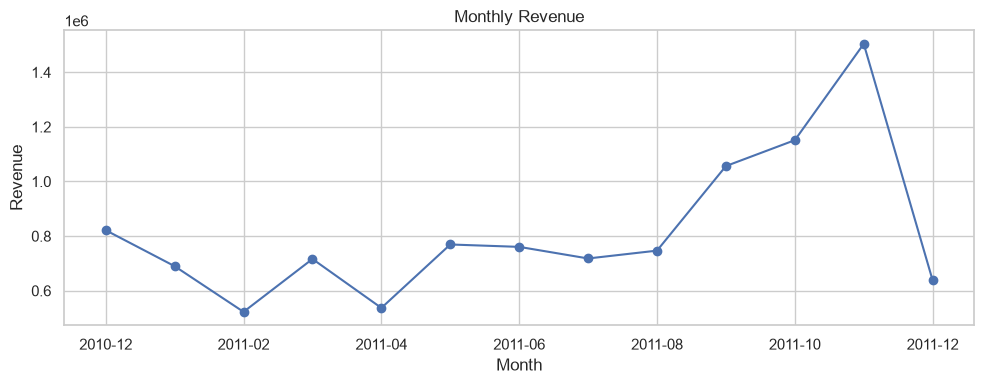

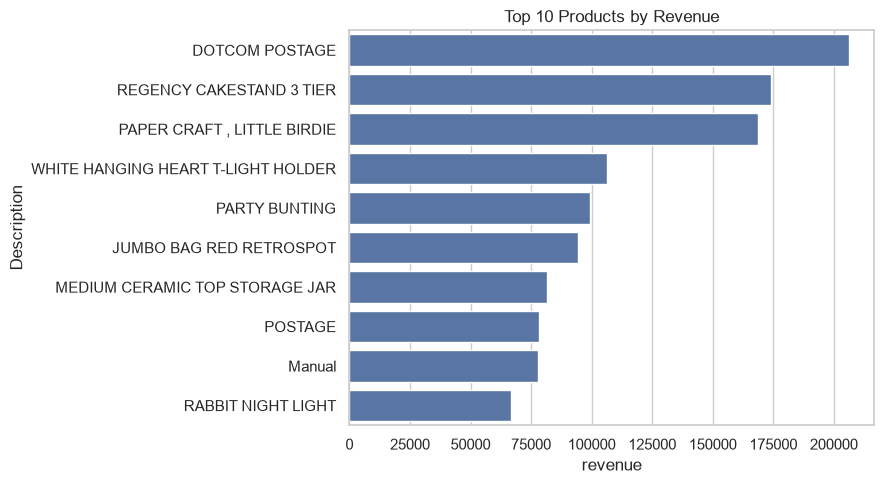

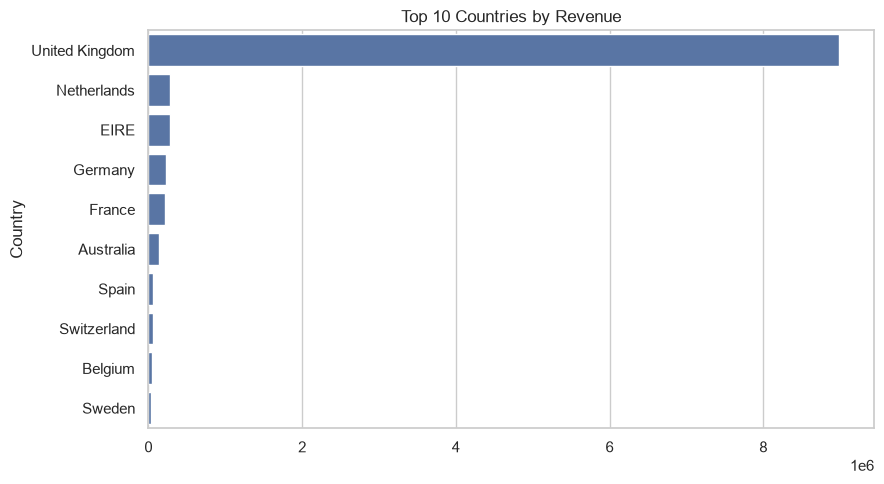

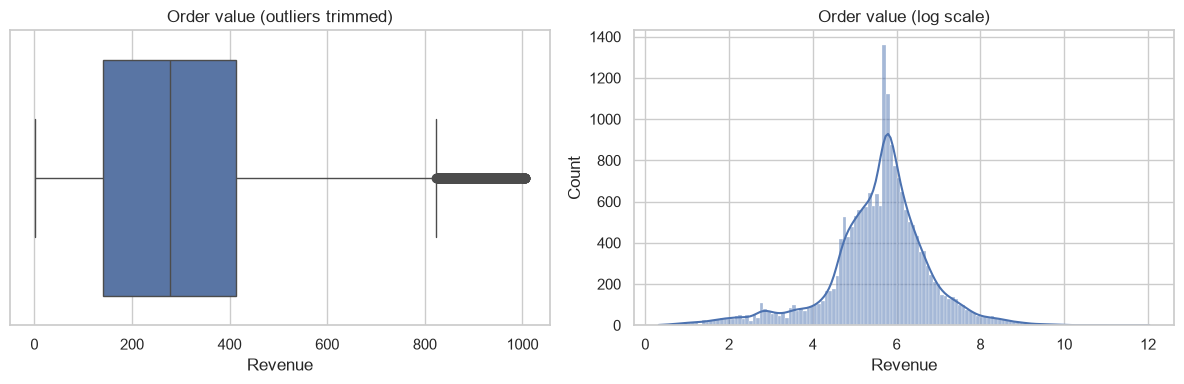

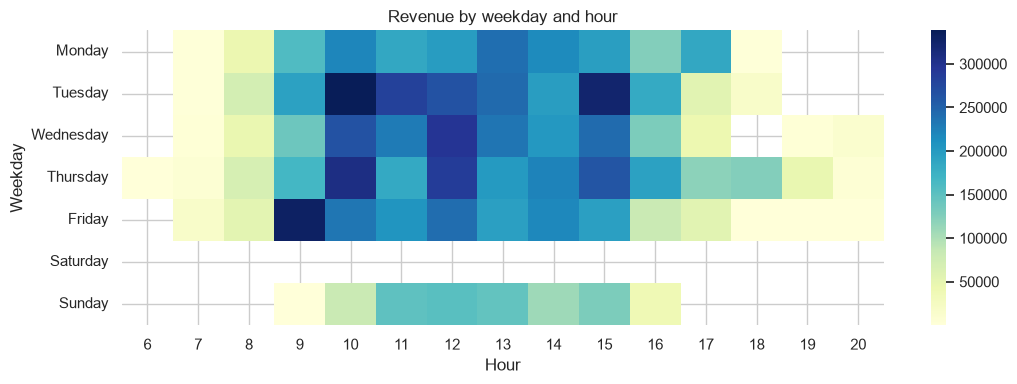

In [13]:
img = "../site/images/"

plt.figure(figsize=(10,4)); monthly.plot(marker="o", title="Monthly Revenue")
plt.ylabel("Revenue"); plt.tight_layout(); plt.savefig(img+"monthly_revenue.png", dpi=150); plt.show()

plt.figure(figsize=(9,5))
sns.barplot(data=top_products.reset_index(), x="revenue", y="Description")
plt.title("Top 10 Products by Revenue"); plt.tight_layout(); plt.savefig(img+"top_products.png", dpi=150); plt.show()

plt.figure(figsize=(9,5))
sns.barplot(x=by_country.head(10).values, y=by_country.head(10).index)
plt.title("Top 10 Countries by Revenue"); plt.tight_layout(); plt.savefig(img+"top_countries.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12,4))
sns.boxplot(x=order_value[order_value < upper], ax=ax[0]); ax[0].set_title("Order value (outliers trimmed)")
sns.histplot(np.log1p(order_value), kde=True, ax=ax[1]); ax[1].set_title("Order value (log scale)")
plt.tight_layout(); plt.savefig(img+"order_distribution.png", dpi=150); plt.show()

heat = sales.pivot_table(index="Weekday", columns="Hour", values="Revenue", aggfunc="sum")
heat = heat.reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])
plt.figure(figsize=(11,4)); sns.heatmap(heat, cmap="YlGnBu")
plt.title("Revenue by weekday and hour"); plt.tight_layout(); plt.savefig(img+"heatmap.png", dpi=150); plt.show()

In [14]:
m = monthly.reset_index()
px.line(m, x="Month", y="Revenue", markers=True, title="Monthly Revenue").write_html("../site/charts/monthly.html")
px.bar(top_products.reset_index(), x="revenue", y="Description", orientation="h",
       title="Top 10 Products").write_html("../site/charts/top_products.html")
c = by_country.head(10).reset_index()
px.bar(c, x="Country", y="Revenue", title="Top 10 Countries").write_html("../site/charts/countries.html")

In [7]:
import sqlite3, pandas as pd

con = sqlite3.connect("../data/ecommerce.db")   # notebook is in notebooks/, so go up one level

query = """
SELECT Description, SUM(Quantity) AS units, ROUND(SUM(Revenue),2) AS revenue
FROM sales GROUP BY Description ORDER BY revenue DESC LIMIT 10;
"""
pd.read_sql(query, con)

,Description,units,revenue
0,DOTCOM POSTAGE,706,206248.77
1,REGENCY CAKESTAND 3 TIER,13851,174156.54
2,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
3,WHITE HANGING HEART T-LIGHT HOLDER,37872,106236.72
4,PARTY BUNTING,18283,99445.23
5,JUMBO BAG RED RETROSPOT,48371,94159.81
6,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
7,POSTAGE,3150,78101.88
8,Manual,6985,77752.82
9,RABBIT NIGHT LIGHT,30739,66870.03
